Clase 010 · `010_importar_formatos` · Primera figura hecha con la interfaz orientada a
objetos de matplotlib: `fig, ax = plt.subplots()`, un día de irradiancia con `scatter` y
la última semana del archivo con `plot`. Aparecen las decisiones que repetirás en cada
figura del curso: tamaño, ventana de tiempo, etiquetas con unidades, rejilla, leyenda y
cómo guardarla en disco. La clase 011 continúa desde aquí.

::: {.callout-important title="Datos"}
El archivo `v7_encoding.csv` no viaja en el repositorio; colócalo en
`clases/010_importar_formatos/data/001_raw/` (se comparte en clase). La libreta guarda
sus figuras en `clases/010_importar_formatos/img/`.
:::

## Librerías

`parse`, de `dateutil`, convierte una cadena como `"2026-04-15"` en una fecha con la que
se puede hacer aritmética. `python-dateutil` llega al proyecto como dependencia de `pandas`,
así que no hay que instalarlo aparte.

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from dateutil.parser import parse

## Leer el CSV

La misma lectura de la libreta anterior: `encoding="cp1252"`, dos filas de encabezado
saltadas, el índice en fechas y las tres irradiancias renombradas. `info()` confirma los
172 433 registros.

In [2]:
f = "../data/001_raw/v7_encoding.csv"
esolmet = pd.read_csv(f,encoding="cp1252",skiprows=2,index_col=0,parse_dates=True)
nombres = {
    "Irradiancia difusa (W/m²)":"dhi",
    "Irradiancia directa (W/m²)":"dni",
    "Irradiancia global (W/m²)":"ghi"
}
esolmet.rename(columns=nombres,inplace=True)
esolmet.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 172433 entries, 2026-04-08 00:00:00 to 2026-08-05 18:04:00
Data columns (total 10 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   dhi                           172433 non-null  float64
 1   dni                           172433 non-null  float64
 2   ghi                           172431 non-null  float64
 3   Presión atmosférica (hPa)     143686 non-null  float64
 4   Precipitación acumulada (mm)  172433 non-null  float64
 5   Humedad relativa (%)          171894 non-null  float64
 6   Temperatura (°C)              172433 non-null  float64
 7   Índice UV                     172433 non-null  float64
 8   Dirección viento (°)          172433 non-null  float64
 9   Velocidad viento (m/s)        172433 non-null  float64
dtypes: float64(10)
memory usage: 14.5 MB


## Un día de irradiancia con `scatter`

`plt.subplots(figsize=(12, 3))` crea la figura y un solo `Axes` y los devuelve juntos; el
tamaño está en pulgadas, ancho por alto. La ventana de tiempo se define con fechas: `f1` es
el 15 de abril y `f2` es un día después (`pd.Timedelta("1D")`).

`ax.scatter` dibuja un punto por registro para `ghi` y `dhi`. Fíjate en que no filtramos el
`DataFrame`: `set_xlim(f1, f2)` sólo recorta la vista, los puntos de los demás días siguen
ahí fuera del cuadro. Las etiquetas llevan unidades y `$^2$` usa la notación matemática de
matplotlib para el superíndice. `tight_layout()` ajusta los márgenes para que nada se corte.

`savefig` guarda la figura dos veces: PNG a 300 dpi para pantalla y PDF, que es vectorial y
se escala sin perder calidad en una tesis. Con el *backend* inline de Jupyter la figura
también se muestra en la celda. Mira la forma: `ghi` sube como campana hasta unos 1000 W/m²
al mediodía y `dhi` se queda cerca de 200; después de las 14 h las nubes rompen la curva.

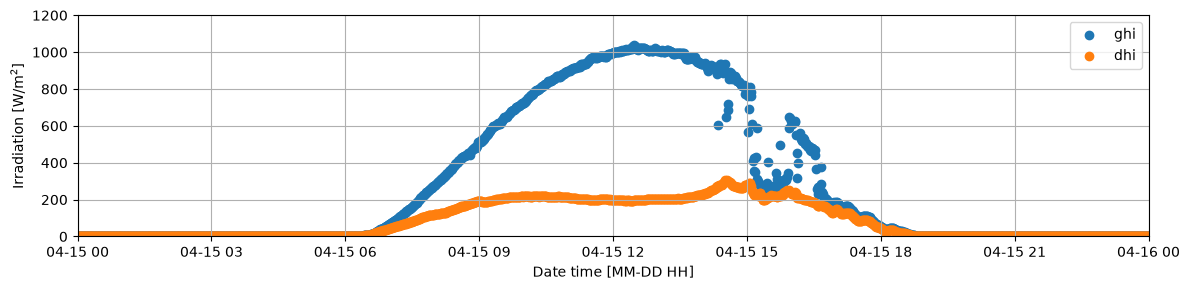

In [33]:
#| label: fig-ghi-dhi-un-dia
#| fig-cap: "Irradiancia global (`ghi`) y difusa (`dhi`) del 15 de abril de 2026 con `ax.scatter`. La global alcanza unos 1000 W/m² al mediodía; a partir de las 14 h las nubes rompen la campana."
#| fig-alt: "Gráfico de dispersión con dos series de puntos, azul para ghi y naranja para dhi, de medianoche a medianoche; la azul forma una campana que llega a 1000 W/m² y se vuelve irregular después de las 14 h, la naranja se mantiene cerca de 200."
fig, ax = plt.subplots(figsize=(12,3))

f1 = parse("2026-04-15")
f2 = f1 + pd.Timedelta("1D")

ax.scatter(esolmet.index,esolmet.ghi,label="ghi")
ax.scatter(esolmet.index,esolmet.dhi,label="dhi")

ax.set_xlim(f1,f2)
ax.set_ylabel("Irradiation [W/m$^2$]")
ax.set_xlabel("Date time [MM-DD HH]")
ax.grid()
ax.set_ylim(0,1200)
ax.legend()
fig.tight_layout()
fig.savefig("../img/irradiation.png",dpi=300)
fig.savefig("../img/irradiation.pdf")


## La última semana con `plot`

Ahora la ventana se calcula desde el final de los datos: `esolmet.index.max()` menos siete
días. `ax.plot(esolmet.ghi, "r-")` dibuja una línea continua roja —el segundo argumento es
una *format string*: color `r`, estilo `-`— y `dhi` toma el color por omisión.

La celda imprime una tupla de dos números antes de la figura: es lo que devuelve
`ax.set_xlim`, los límites en la representación interna de fechas de matplotlib (días desde
una fecha de referencia). Para silenciarlo, termina la línea con `;` o pon `set_xlim` antes
de otra instrucción. En la figura se ven siete campanas y los días nublados (30 de julio y
3 de agosto) con la irradiancia directa recortada.

(np.float64(20663.75277777778), np.float64(20670.75277777778))

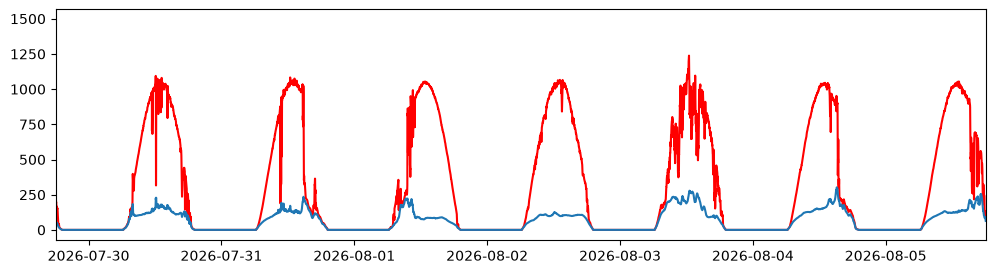

In [48]:
#| label: fig-ghi-dhi-ultima-semana
#| fig-cap: "Última semana del archivo (30 de julio a 5 de agosto de 2026) con `ax.plot`: `ghi` en rojo y `dhi` en azul. Dos de los siete días muestran la irradiancia recortada por nubes."
#| fig-alt: "Gráfico de líneas con siete campanas diarias en rojo que llegan a 1000 W/m² y una línea azul baja; el 30 de julio y el 3 de agosto la línea roja tiene caídas abruptas."
dias = pd.Timedelta("7D")

fig, ax = plt.subplots(figsize=(12,3))

f1 = esolmet.index.max() - dias
f2 = f1  + dias

ax.plot(esolmet.ghi,"r-",label="ghi")
ax.plot(esolmet.dhi,label="dhi")
ax.set_xlim(f1,f2)

## ¿Hasta cuándo llegan los datos?

El último registro del archivo, que es el extremo derecho de la figura anterior.

In [44]:
esolmet.index.max()

Timestamp('2026-08-05 18:04:00')